Sketch

In [18]:
import numpy as np
import matplotlib.pyplot as plt

data = np.load("data/raw/raw/full_numpy_bitmap_aircraft carrier.npy")

data.shape

(116504, 784)

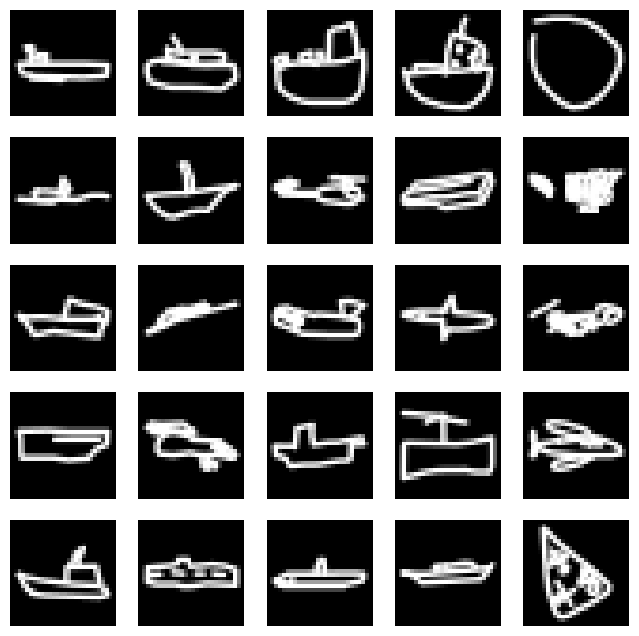

In [19]:
data = data[:500]

plt.figure(figsize=(8, 8))

for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(data[i].reshape(28, 28), cmap="gray")
    plt.axis("off")

plt.show()

In [31]:
import numpy as np

index_categories = [
    "aircraft carrier", "airplane", "ambulance", "angel", "ant",
    "anvil", "basket", "basketball", "bed"
]

heldout_categories = ["alarm clock", "animal migration"]

data = np.load(
    "data/raw/raw/full_numpy_bitmap_aircraft carrier.npy"
)

data.shape

(116504, 784)

In [32]:
data = np.load(
    "data/raw/raw/full_numpy_bitmap_aircraft carrier.npy"
)
data = data[np.random.choice(len(data), 500, replace=False)]

data = data.reshape(-1, 28, 28)

gallery = data[:450]
queries = data[450:]

print(gallery.shape)
print(queries.shape)

(450, 28, 28)
(50, 28, 28)


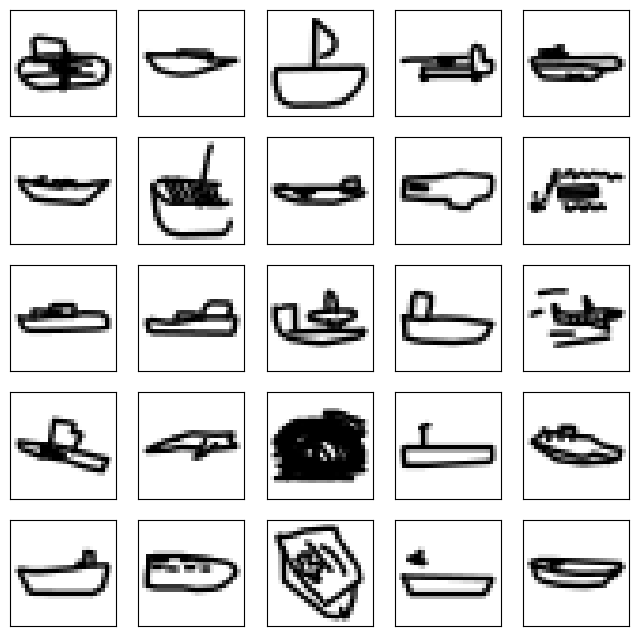

In [33]:
plt.figure(figsize=(8, 8))

for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(gallery[i], cmap="binary")
    plt.xticks([])
    plt.yticks([])

plt.show()

In [34]:
import os

files = os.listdir("data/raw/raw")

for file in files:
    print(file)

full_numpy_bitmap_aircraft carrier.npy
full_numpy_bitmap_airplane.npy
full_numpy_bitmap_alarm clock.npy
full_numpy_bitmap_ambulance.npy
full_numpy_bitmap_angel.npy
full_numpy_bitmap_animal migration.npy
full_numpy_bitmap_ant.npy
full_numpy_bitmap_anvil.npy
full_numpy_bitmap_apple.npy.opdownload
full_numpy_bitmap_arm.npy.opdownload
full_numpy_bitmap_asparagus.npy.opdownload
full_numpy_bitmap_axe.npy.opdownload
full_numpy_bitmap_backpack.npy.opdownload
full_numpy_bitmap_banana.npy.opdownload
full_numpy_bitmap_bandage.npy.opdownload
full_numpy_bitmap_barn.npy.opdownload
full_numpy_bitmap_baseball bat.npy.opdownload
full_numpy_bitmap_baseball.npy.opdownload
full_numpy_bitmap_basket.npy
full_numpy_bitmap_basketball.npy
full_numpy_bitmap_bat.npy.opdownload
full_numpy_bitmap_bed.npy
full_numpy_bitmap_bee.npy.opdownload


In [35]:
from pathlib import Path

print(list(Path("data/raw/raw").glob("*.npy")))

[WindowsPath('data/raw/raw/full_numpy_bitmap_aircraft carrier.npy'), WindowsPath('data/raw/raw/full_numpy_bitmap_airplane.npy'), WindowsPath('data/raw/raw/full_numpy_bitmap_alarm clock.npy'), WindowsPath('data/raw/raw/full_numpy_bitmap_ambulance.npy'), WindowsPath('data/raw/raw/full_numpy_bitmap_angel.npy'), WindowsPath('data/raw/raw/full_numpy_bitmap_animal migration.npy'), WindowsPath('data/raw/raw/full_numpy_bitmap_ant.npy'), WindowsPath('data/raw/raw/full_numpy_bitmap_anvil.npy'), WindowsPath('data/raw/raw/full_numpy_bitmap_basket.npy'), WindowsPath('data/raw/raw/full_numpy_bitmap_basketball.npy'), WindowsPath('data/raw/raw/full_numpy_bitmap_bed.npy')]


Indexed: aircraft carrier
Indexed: airplane
Indexed: ambulance
Indexed: angel
Indexed: ant
Indexed: anvil
Indexed: basket
Indexed: basketball
Indexed: bed
Held-out: alarm clock
Held-out: animal migration

Saved: data\subset.npz
gallery_images (4050, 28, 28)
gallery_labels (4050,)
query_images (450, 28, 28)
query_labels (450,)
heldout_images (100, 28, 28)
heldout_labels (100,)


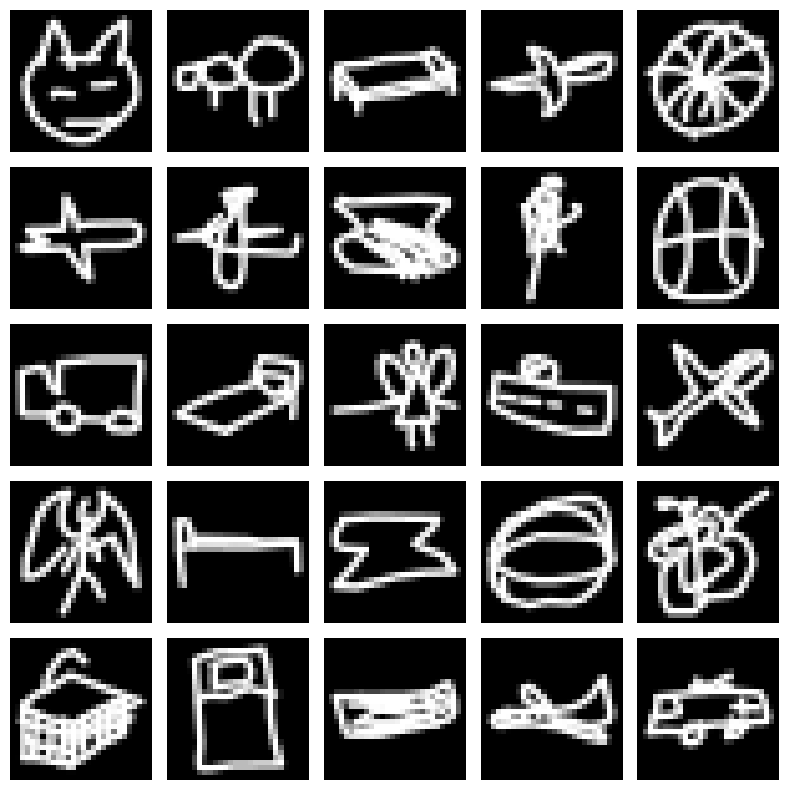

In [38]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Settings
SEED = 42
RAW_DIR = Path("data/raw/raw")
OUTPUT_PATH = Path("data/subset.npz")

# Categories used for searching
index_categories = [
    "aircraft carrier", "airplane", "ambulance", "angel", "ant",
    "anvil", "basket", "basketball", "bed"
]

# Categories not included in the gallery
heldout_categories = ["alarm clock", "animal migration"]

# All categories
all_categories = index_categories + heldout_categories

# Fixed random seed
rng = np.random.default_rng(SEED)


# Get the file path for a category
def category_file(category):
    return RAW_DIR / f"full_numpy_bitmap_{category}.npy"


# Load a random sample of doodles
def load_sample(category, count):
    path = category_file(category)

    data = np.load(path, mmap_mode="r")

    if len(data) < count:
        raise ValueError(f"Not enough images in {category}")

    selected = rng.choice(len(data), size=count, replace=False)

    images = np.asarray(data[selected], dtype=np.uint8)

    return images.reshape(-1, 28, 28)


# Check that all required files exist
missing = [
    str(category_file(category))
    for category in all_categories
    if not category_file(category).is_file()
]

if missing:
    raise FileNotFoundError(
        "Missing dataset files:\n" + "\n".join(missing)
    )


# Store images and labels
gallery_images = []
gallery_labels = []

query_images = []
query_labels = []

heldout_images = []
heldout_labels = []


# Sample 500 doodles from each index category
for category in index_categories:
    images = load_sample(category, 500)

    gallery_images.extend(images[:450])
    query_images.extend(images[450:])

    gallery_labels.extend([category] * 450)
    query_labels.extend([category] * 50)

    print("Indexed:", category)


# Sample 50 doodles from each held-out category
for category in heldout_categories:
    images = load_sample(category, 50)

    heldout_images.extend(images)
    heldout_labels.extend([category] * 50)

    print("Held-out:", category)


# Convert lists into NumPy arrays
result = {
    "gallery_images": np.asarray(gallery_images, dtype=np.uint8),
    "gallery_labels": np.asarray(gallery_labels),
    "query_images": np.asarray(query_images, dtype=np.uint8),
    "query_labels": np.asarray(query_labels),
    "heldout_images": np.asarray(heldout_images, dtype=np.uint8),
    "heldout_labels": np.asarray(heldout_labels)
}


# Save everything
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

np.savez_compressed(OUTPUT_PATH, **result)

print("\nSaved:", OUTPUT_PATH)

for key, value in result.items():
    print(key, value.shape)


# Plot a 5 × 5 grid of random gallery doodles
plot_indices = rng.choice(
    len(result["gallery_images"]), size=25, replace=False
)

plt.figure(figsize=(8, 8))

for i, idx in enumerate(plot_indices):
    plt.subplot(5, 5, i + 1)
    plt.imshow(result["gallery_images"][idx], cmap="gray")
    plt.axis("off")

plt.tight_layout()
plt.show()